In [40]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test multiple mcmc (one run)

In [41]:
# Define parameters & model
N = 1000
d = 4
beta = 0.4
maxiter = 10**6
#G, couplings = create_ER_graph(N, d, coupling_type='gauss')
G, couplings, N = create_lattice_graph(50, 2, model='RL_sg', periodic=True)
#G, couplings = create_complete_graph(N, model='CW')

max_degree = max(d for _, d in G.degree())
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/(d-1))
beta_dob = np.arctanh(1/d)
beta_uni, beta_SG, max_degree, beta_dob, N

(0.34657359027997264, 0.5493061443340549, 4, 0.25541281188299536, 2500)

In [42]:
# Run BC forward
nb_star_state, nb_unresolved_confs, final_step = multiple_mcmc(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, n_configs=10, lazy=False)

Coalescence achieved at iteration 262054.


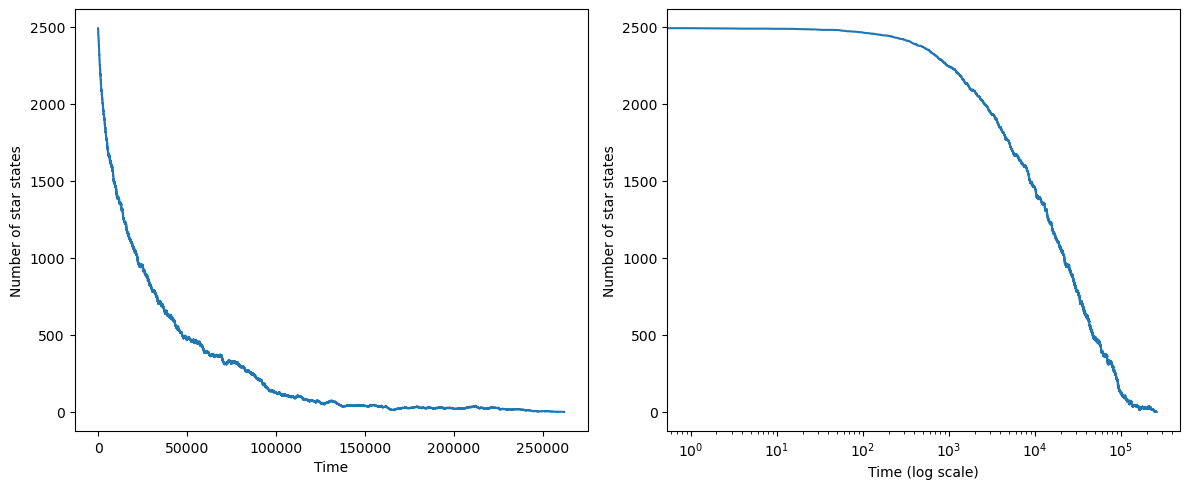

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

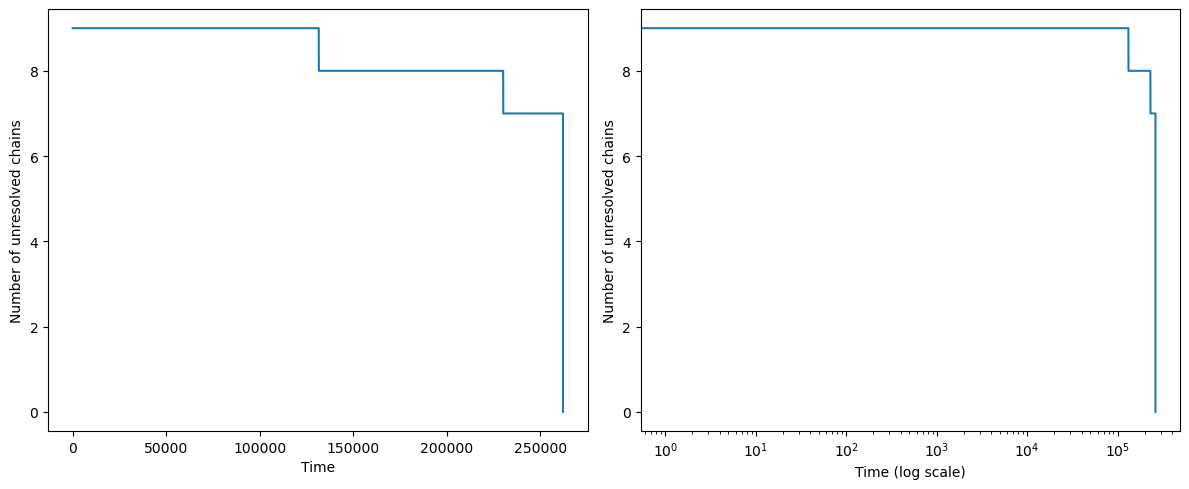

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_unresolved_confs)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of unresolved chains')

ax2.plot(nb_unresolved_confs)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of unresolved chains')

plt.tight_layout()
plt.show()

# Coalescence times

In [6]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [18]:
beta = 0.4
coup_type = 'gauss'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 3    
nb_itermax = 10**7
N_list = [100, 250, 500, 1000, 2500, 5000]
csv_path = f"../results/tmp/coal_time_DS_ER_{coup_type}_d{d}.csv"

In [19]:
df = compute_coal_time_DS(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, n_configs=100, lazy=False)

N=100
Coalescence achieved at iteration 3590.
Coalescence achieved at iteration 7027.
Coalescence achieved at iteration 4353.
N=250
Coalescence achieved at iteration 32322.
Coalescence achieved at iteration 90592.
Coalescence achieved at iteration 42191.
N=500
Coalescence achieved at iteration 207768.
Coalescence achieved at iteration 129097.
Coalescence achieved at iteration 75638.
N=1000
Coalescence achieved at iteration 514473.
Coalescence achieved at iteration 881908.
Coalescence achieved at iteration 583406.
N=2500
N=5000


In [21]:
if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [22]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['n_configs'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows

df

[0.3 0.4]
['F_beta_Glauber']
[False]
[100]
[3]
[10000000]
[ 100  250  500 1000 2500 5000]
12


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.3,F_beta_Glauber,False,100,3,10000000,100,3,3887.333333,2285.513558
1,0.3,F_beta_Glauber,False,100,3,10000000,250,3,12806.000000,2828.010372
2,0.3,F_beta_Glauber,False,100,3,10000000,500,3,40421.333333,14493.446803
3,0.3,F_beta_Glauber,False,100,3,10000000,1000,3,86755.333333,7503.352155
4,0.3,F_beta_Glauber,False,100,3,10000000,2500,3,243859.333333,43586.049866
5,0.3,F_beta_Glauber,False,100,3,10000000,5000,3,569781.333333,78928.275602
6,0.4,F_beta_Glauber,False,100,3,10000000,100,3,4990.000000,1473.673189
7,0.4,F_beta_Glauber,False,100,3,10000000,250,3,55035.000000,25463.365541
8,0.4,F_beta_Glauber,False,100,3,10000000,500,3,137501.000000,54268.189805
9,0.4,F_beta_Glauber,False,100,3,10000000,1000,3,659929.000000,159465.663918


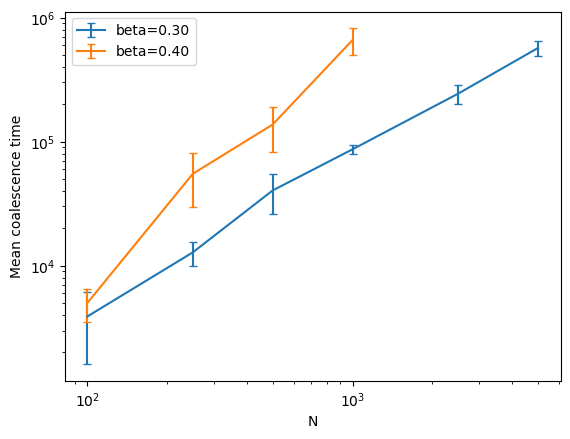

In [23]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

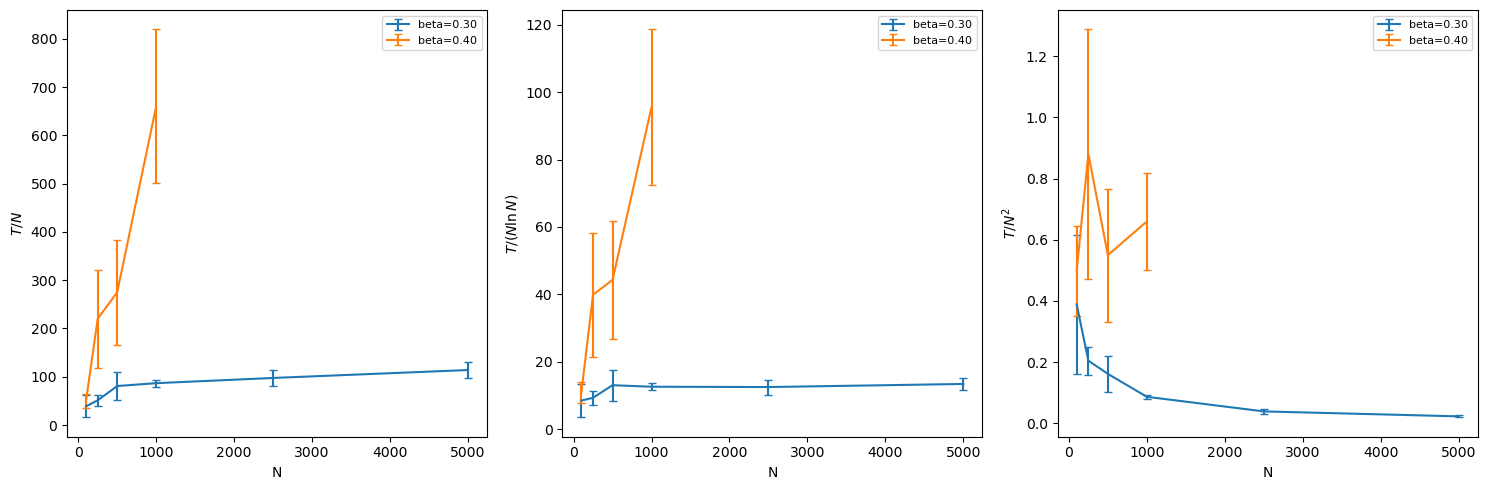

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

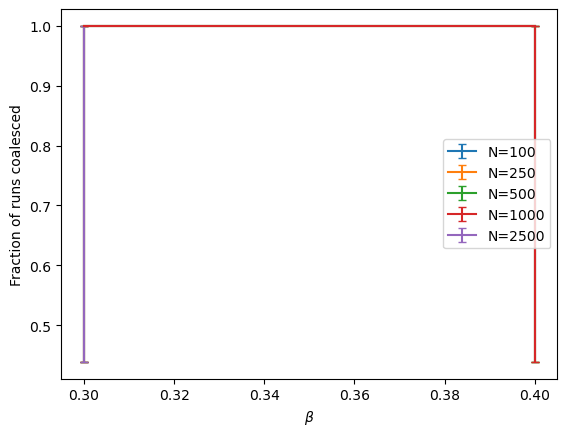

In [25]:
N_to_exclude = [5000]
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

# Evolution star states & nb configs

In [45]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [50]:
N = 5000
beta_list = [0.2, 0.23, 0.25, 0.26, 0.27]
#beta_list = [0.3, 0.31, 0.32, 0.33, 0.34]
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 10    
nb_itermax = 10**7

In [51]:
dfs = []
for beta in beta_list:
    print(f"beta={beta}")
    df_beta = compute_nb_star_DS(N, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, n_configs=10, lazy=False, n_points=10000)
    dfs.append(df_beta)

df = pd.concat(dfs, ignore_index=True)

csv_path = f"../results/tmp/nb_star_DS_ER_{coup_type}_d{d}_N{N}.csv"
df.to_csv(csv_path, index=False)


beta=0.2
Coalescence achieved at iteration 209696.
Coalescence achieved at iteration 178359.
Coalescence achieved at iteration 166449.
Coalescence achieved at iteration 242521.
Coalescence achieved at iteration 201636.
Coalescence achieved at iteration 151867.
Coalescence achieved at iteration 192021.
Coalescence achieved at iteration 292424.
Coalescence achieved at iteration 298789.
Coalescence achieved at iteration 205915.
beta=0.23
Coalescence achieved at iteration 289228.
Coalescence achieved at iteration 424303.
Coalescence achieved at iteration 429693.
Coalescence achieved at iteration 216114.
Coalescence achieved at iteration 325854.
Coalescence achieved at iteration 356896.
Coalescence achieved at iteration 299894.
Coalescence achieved at iteration 404415.
Coalescence achieved at iteration 355685.
Coalescence achieved at iteration 292725.
beta=0.25
Coalescence achieved at iteration 730843.
Coalescence achieved at iteration 493623.
Coalescence achieved at iteration 549566.
Coale

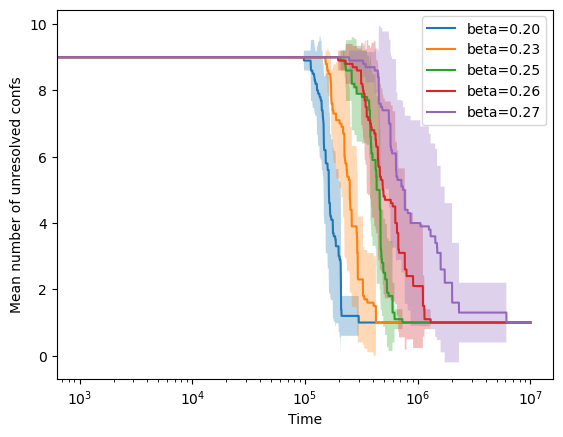

In [55]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_confs'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_confs'] - sub_df['std_nb_confs'],
                     sub_df['mean_nb_confs'] + sub_df['std_nb_confs'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of unresolved confs')
plt.legend()
plt.show()

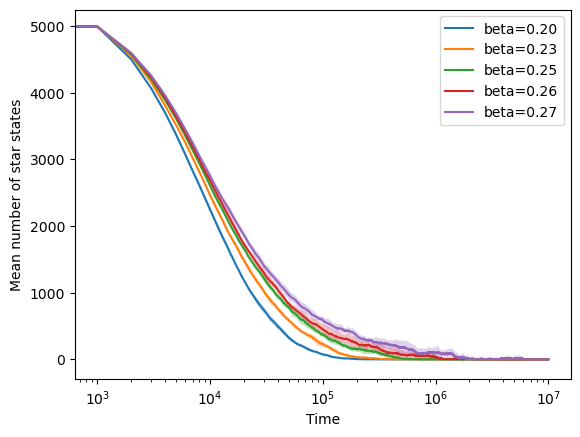

In [52]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

C = 0.082, R²=0.9521


/tmp/ipykernel_10969/1547148418.py:6: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


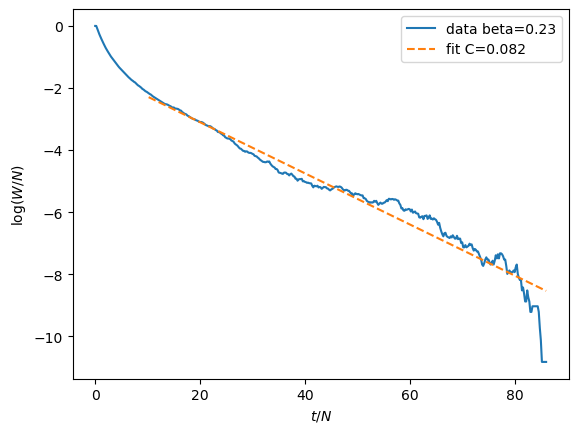

In [53]:
beta = 0.23
sub_df = df[df['beta'] == beta].sort_values('time')
N = sub_df['N'].values[0]

t_over_N = sub_df['time'].values / N
log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

from scipy.stats import linregress

mask = (t_over_N > 10)  & (log_W_over_N > -np.inf) & np.isfinite(log_W_over_N)
slope, intercept, r, p, se = linregress(t_over_N[mask], log_W_over_N[mask])
C = -slope
print(f"C = {C:.3f}, R²={r**2:.4f}")

plt.plot(t_over_N, log_W_over_N, label=f'data beta={beta:.2f}')
plt.plot(t_over_N[mask], intercept + slope * t_over_N[mask], '--', label=f'fit C={C:.3f}')
plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend()
plt.show()

/tmp/ipykernel_10969/3084721683.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_10969/3084721683.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_10969/3084721683.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_10969/3084721683.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


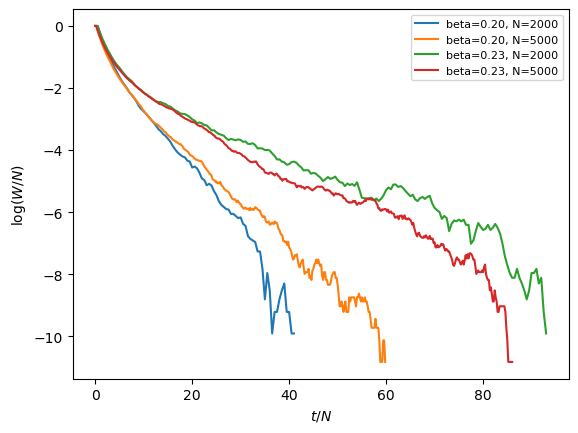

In [54]:
for beta in [0.2, 0.23]:
    for N in [2000, 5000]:
        csv_path = f"../results/tmp/nb_star_DS_ER_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        plt.plot(t_over_N, log_W_over_N, label=f'beta={beta:.2f}, N={N}')

plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend(fontsize=8)
plt.show()